# 1. Data preparation and EDA (Stages 2, 3, 6)

Outputs come from `python -m src.prepare_data` and `python -m src.eda`.
This notebook only shows them.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
import pandas as pd
from IPython.display import Image, display
pd.set_option("display.width", 160)

def show(name):
    display(Image(f"../reports/figures/{name}.png"))

def table(name):
    return pd.read_csv(f"../reports/tables/{name}.csv")

## Stage 3: data preparation (A1)
Rows and columns after each step:

In [2]:
table("prep_summary")

,step,rows,columns,inverters
0,raw 5-min inverter rows,4766698,4,44
1,averaged to 15 min,1588901,5,44
2,full 06:00-17:45 grid,1588901,5,44
3,merged with weather + metadata,1588901,16,44
4,coverage filter (>= 70 %),1588901,17,44


**Finding.** All 4,766,698 five-minute rows become 1,588,901 fifteen-minute rows for 44 inverters. Rebuilding the full 06:00-17:45 grid adds no rows (gaps already appear as empty rows). The lowest daylight coverage is 88.6 %, so no inverter is dropped by the 70 % filter.

## A1 Q1: power vs irradiance

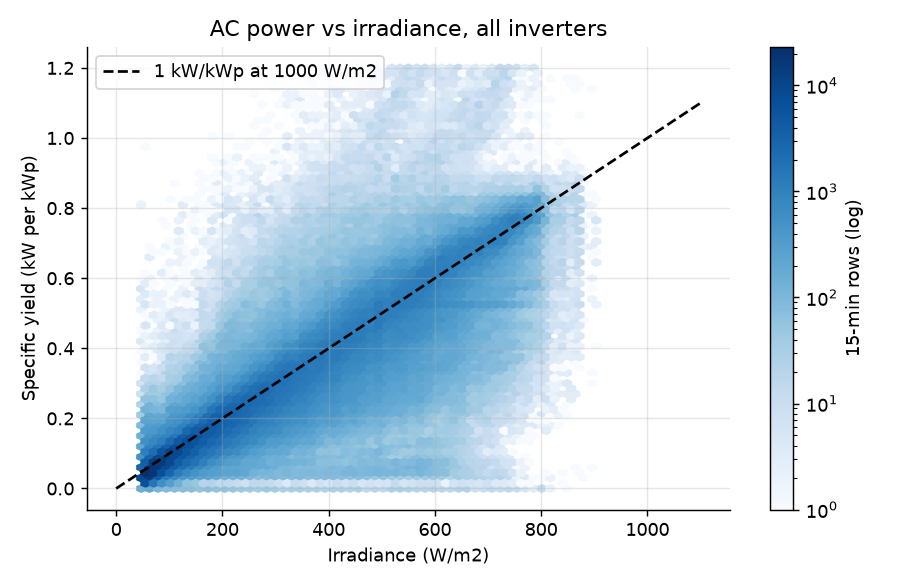

In [3]:
show("eda_a1_power_vs_irradiance")

**Finding.** Output rises in a straight line with sunlight. The flat ceiling near 0.75-0.8 kW/kWp is inverter clipping; points at zero in full sun are outages. **Decision:** health = actual / expected power.

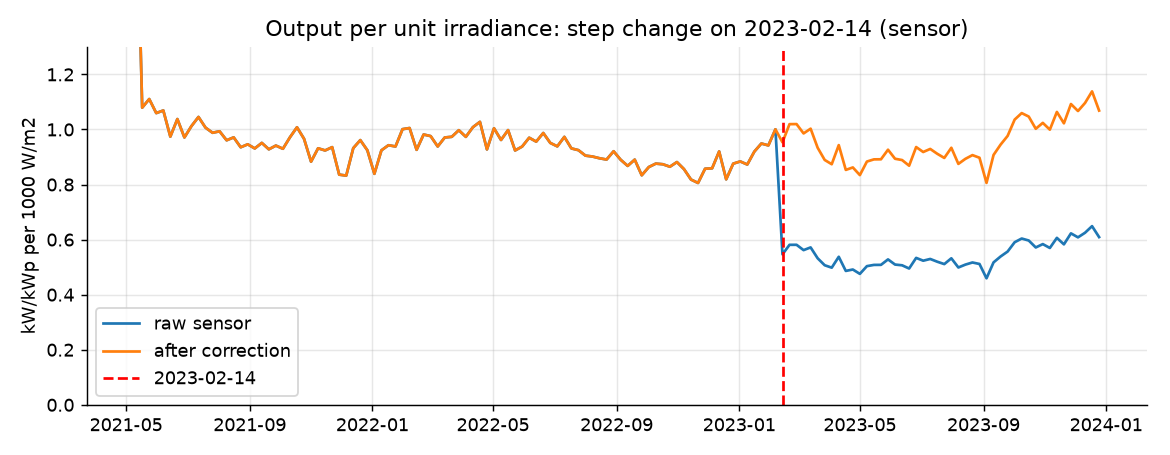

,month,pr_2022,pr_2023,ratio
0,2,0.9872,0.5615,0.5688
1,3,0.9607,0.5561,0.5789
2,4,0.9893,0.5063,0.5118
3,5,0.9865,0.5030,0.5099
4,6,0.9666,0.5139,0.5316
5,7,0.9392,0.5214,0.5552
6,8,0.8997,0.5128,0.5700
7,9,0.8830,0.5140,0.5821
8,10,0.8661,0.5899,0.6811
9,11,0.8445,0.5938,0.7031


In [4]:
show("eda_a1_sensor_change")
table("irradiance_correction")

**Finding.** Output per unit of sunlight drops from about 0.9 to 0.55 for every inverter in the week of 2023-02-14: the sensor changed, not the inverters. The monthly 2023/2022 ratios are 0.51-0.72, median 0.570. **Decision:** irradiance from that day is multiplied by 0.570 (orange line). Without it half of 2023 was labelled Faulty.

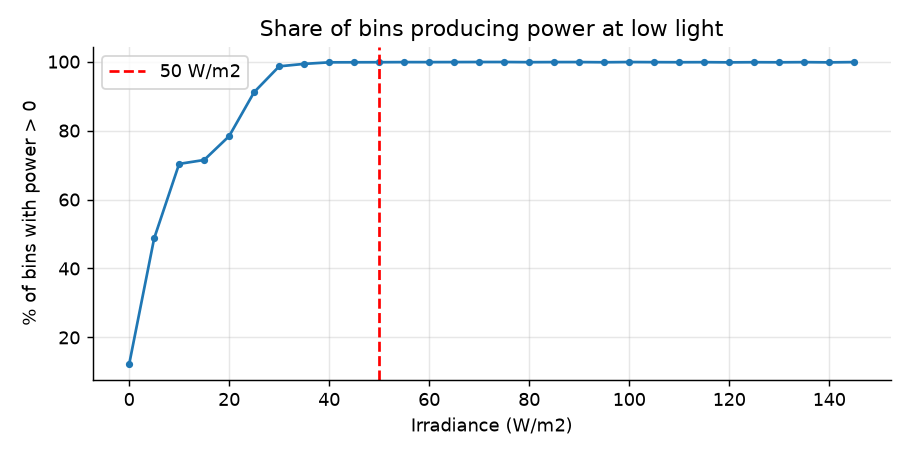

In [5]:
show("eda_a1_night_threshold")

**Finding.** 12 % of bins produce power at 0-5 W/m2, 78 % at 20-25 W/m2 and 99.8 % from 45-50 W/m2. **Decision:** 50 W/m2 marks daylight (coverage, outage counting); the health score needs at least 100 W/m2.

## A1 Q2: gaps and offline events

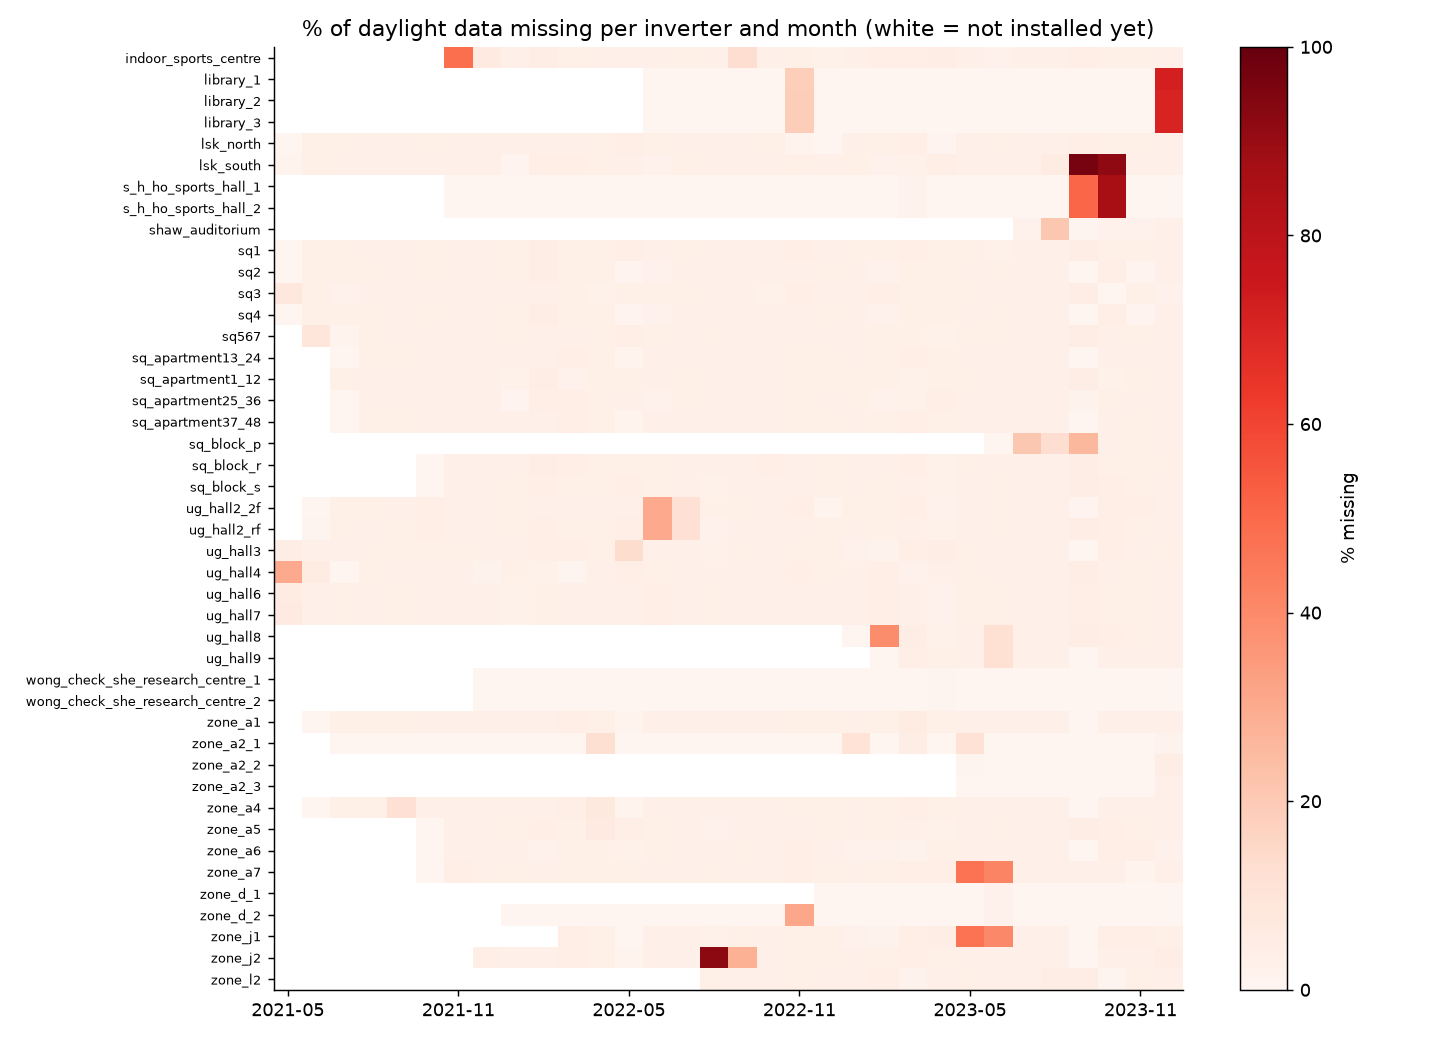

In [6]:
show("eda_a1_gap_heatmap")

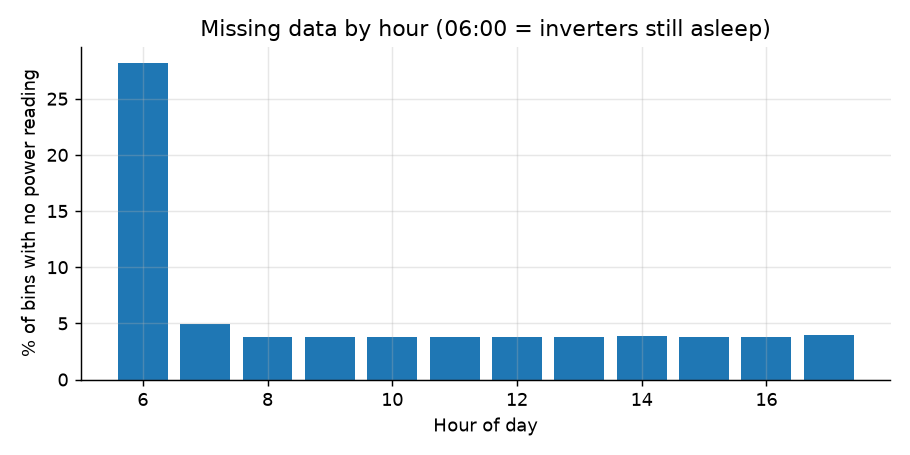

In [7]:
show("eda_a1_missing_by_hour")

**Finding.** About 4 % of daylight data is missing in a normal month; long outages hit LSK South (Sep-Oct 2023, up to 97 %), Zone J2 (Aug 2022), S H Ho (Oct 2023) and Library (Dec 2023), often all inverters of a station at once. The 06:00 hour is 28 % missing (inverters still asleep), every other hour 3.8 %. **Decision:** outages are events (feature `minutes_offline_24h`), not gaps to fill; only daylight bins count.

## A2 Q1: temperature effect

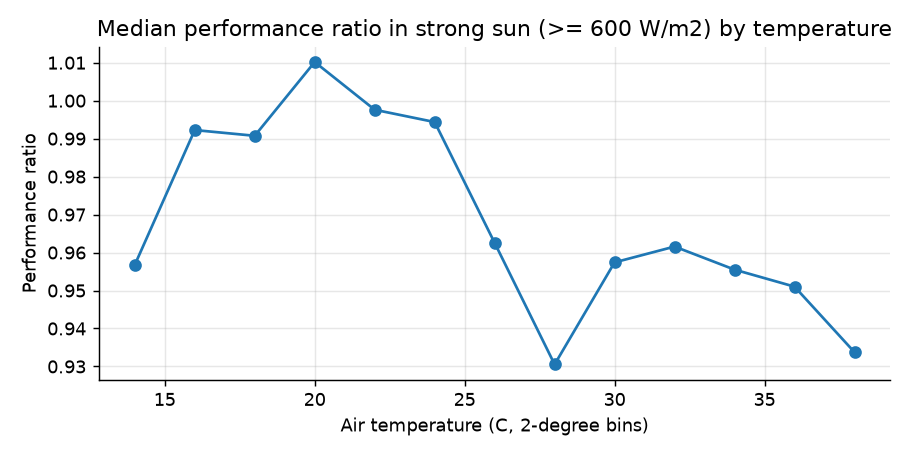

In [8]:
show("eda_a2_temperature_effect")

**Finding.** In strong sun the performance ratio is 0.99-1.01 at 16-24 C and 0.93-0.96 at 28-38 C, about 5 % lower when it is hot. **Decision:** temperature stays a feature.

## A2 Q2: feature correlation

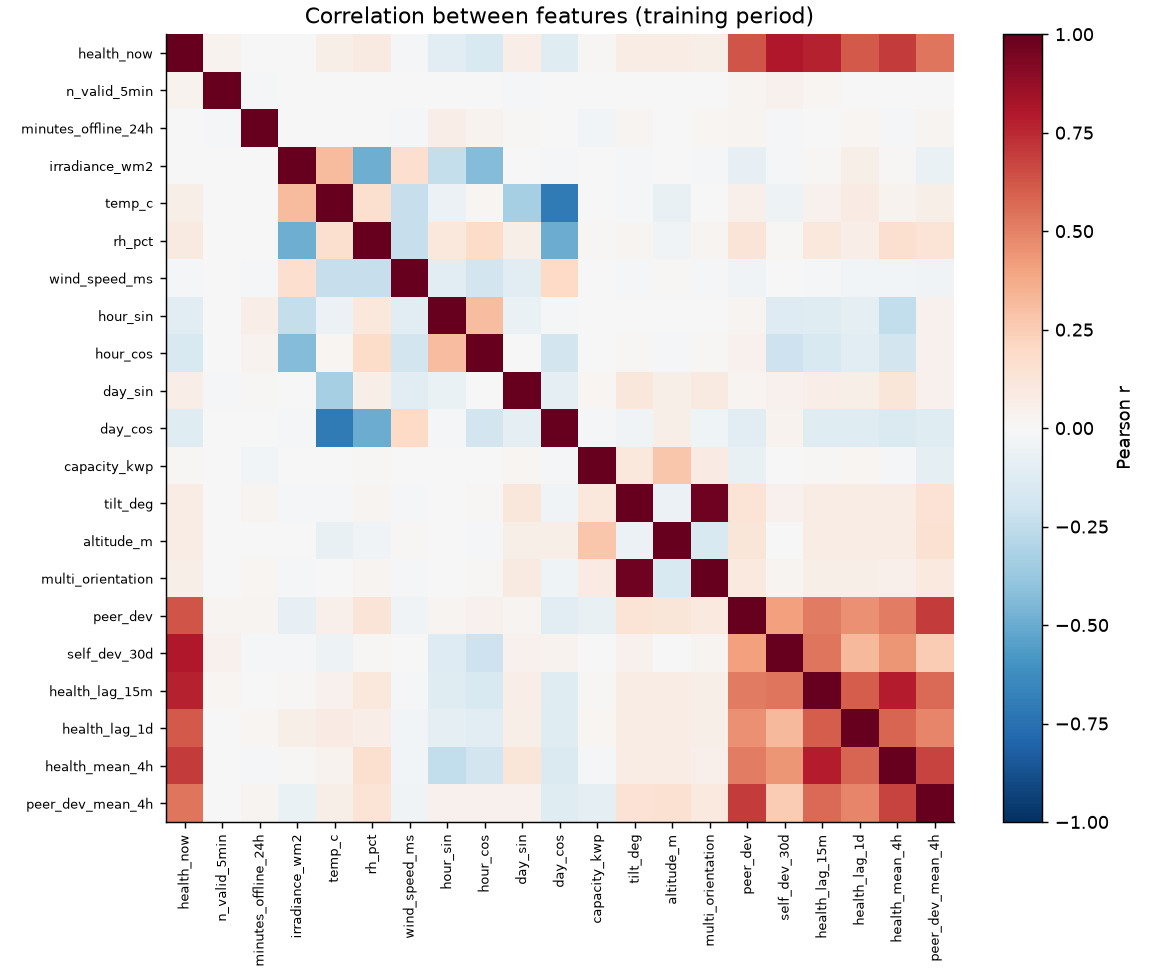

In [9]:
show("eda_a2_feature_correlation")

**Finding.** Only `tilt_deg` and `multi_orientation` are almost the same (r = 0.97). **Decision:** drop `multi_orientation`.

## B1 Q1: degradation over the years

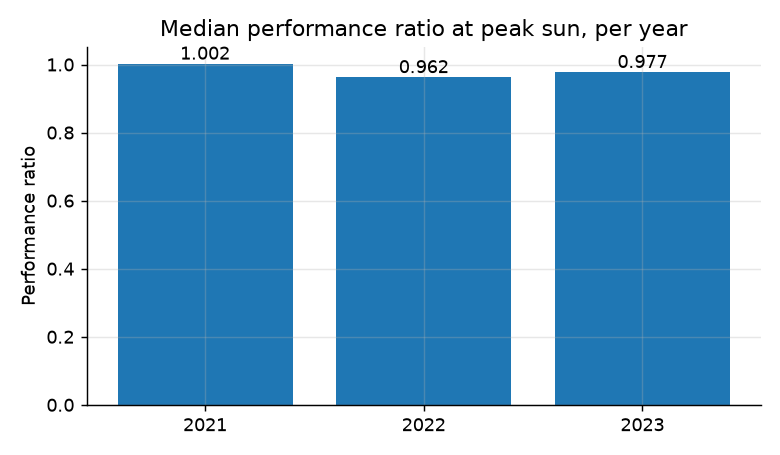

In [10]:
show("eda_b1_degradation")

**Finding.** Median peak-sun performance ratio: 1.002 (2021, May-Dec), 0.962 (2022), 0.977 (2023). No clear yearly decline. **Decision:** no degradation feature; three years is too short to separate ageing from weather and the sensor correction.

## B1 Q2: underperforming inverters

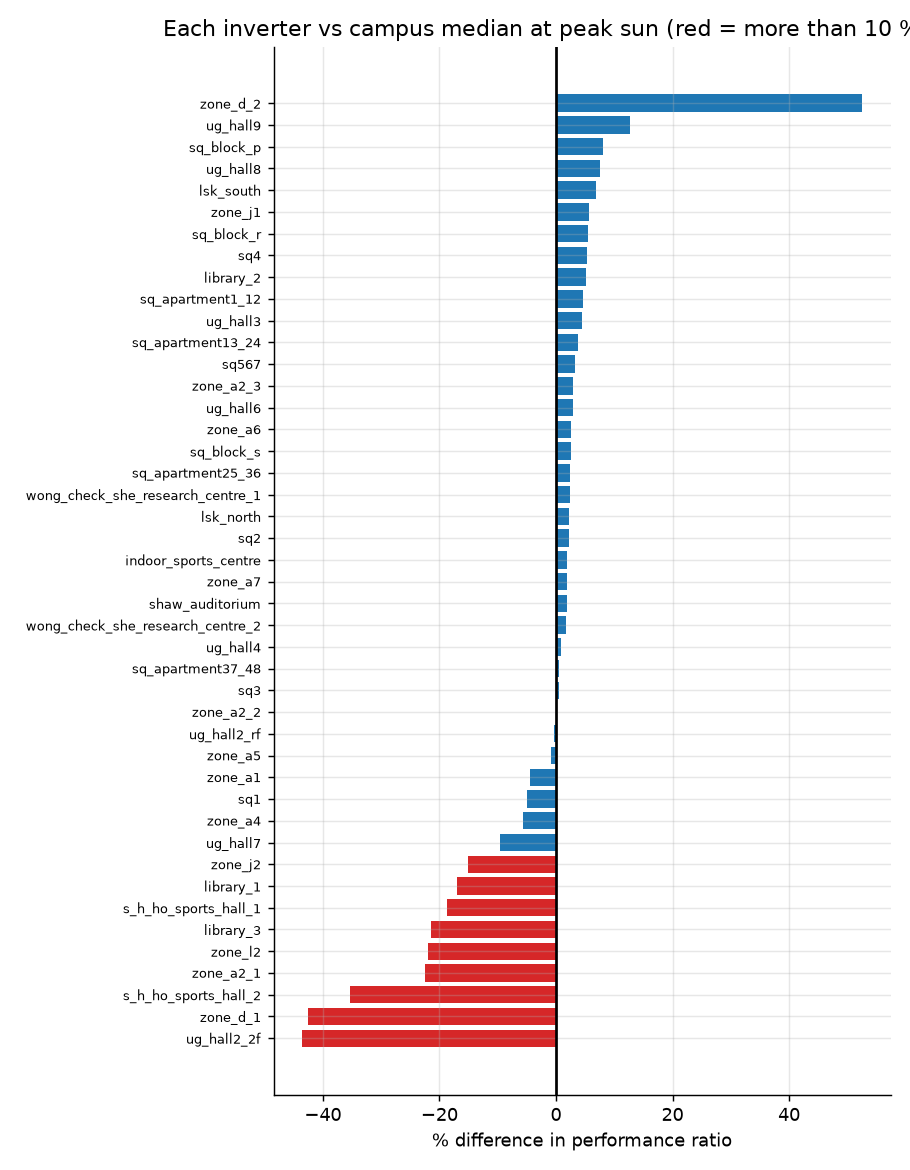

In [11]:
show("eda_b1_underperformers")

**Finding.** Nine inverters are more than 10 % below the campus median at peak sun (worst UG Hall2 2F -44 %, Zone D 1 -43 %, S H Ho 2 -35 %). Zone D 2 is +53 %, which is physically impossible: the Zone D capacities in the metadata are inconsistent. **Decision:** peer deviation becomes a feature; Zone D is listed as a limitation.

## B2 Q1: seasonality

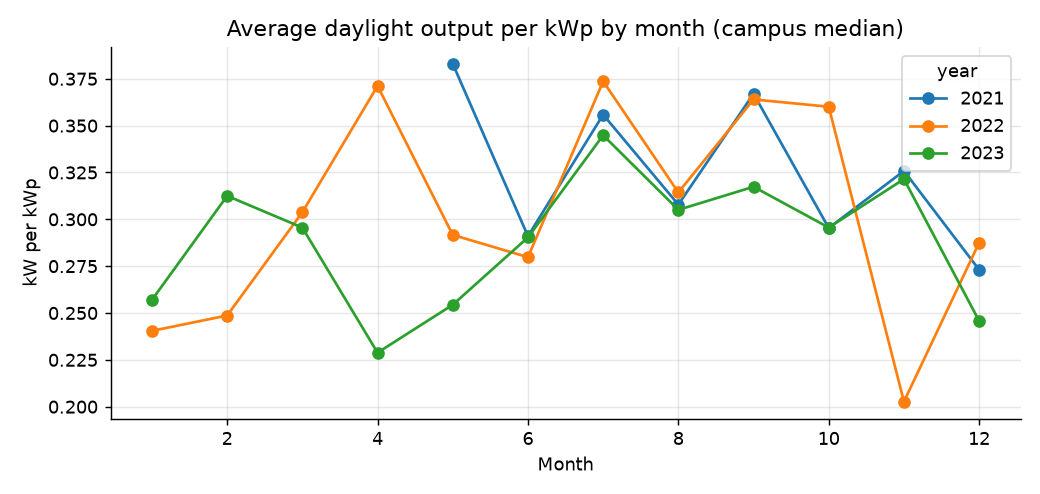

In [12]:
show("eda_b2_seasonality")

**Finding.** Average daylight output per kWp varies from about 0.20 to 0.38 between months, and the same month differs strongly between years (April 2022: 0.37, April 2023: 0.23). **Decision:** chronological split and day-of-year features.

## B2 Q2: class distribution

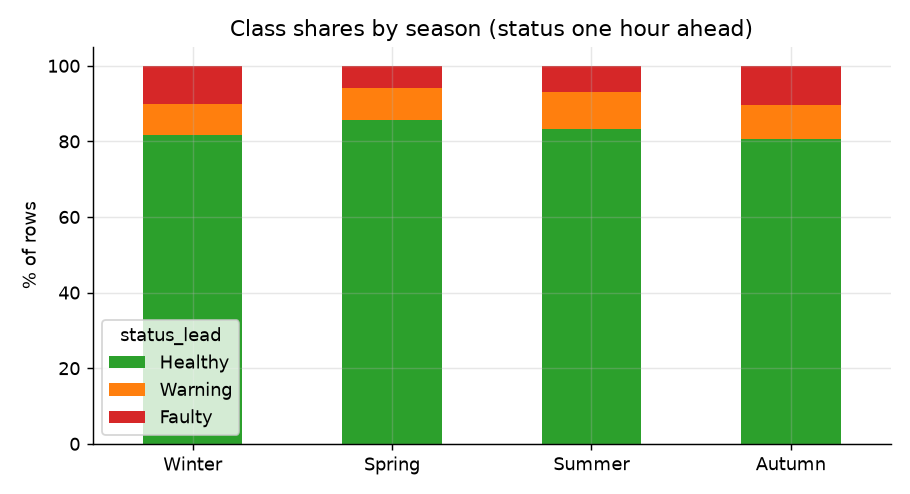

In [13]:
show("eda_b2_class_distribution")

**Finding.** Faulty is 6-10 % of rows depending on the season (Winter 10.1 %, Spring 6.0 %, Summer 7.0 %, Autumn 10.3 %). **Decision:** handle the imbalance (notebook 02) and judge models by Faulty recall and macro-F1, not accuracy.